In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/abhigyanbhatnagar/aesthetic-score-model-weights/saclogosava1-l14-linearMSE.pth


In [7]:
import torch
from diffusers import StableDiffusionSAGPipeline

In [8]:
torch.cuda.is_available()

True

In [9]:
MODEL_ID = "runwayml/stable-diffusion-v1-5"

In [14]:
pipe = StableDiffusionSAGPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
).to("cuda")

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

The StableDiffusionSAGPipeline has been deprecated and will not receive bug fixes or feature updates after Diffusers version 0.33.1. 


In [15]:
prompt = "a cat and a frog"

seed = 6141
generator = torch.Generator("cuda").manual_seed(seed)

images = pipe(
    prompt=prompt,
    guidance_scale=7.5,
    generator=generator,
    num_inference_steps=50,
).images

image = images[0]

  0%|          | 0/50 [00:00<?, ?it/s]

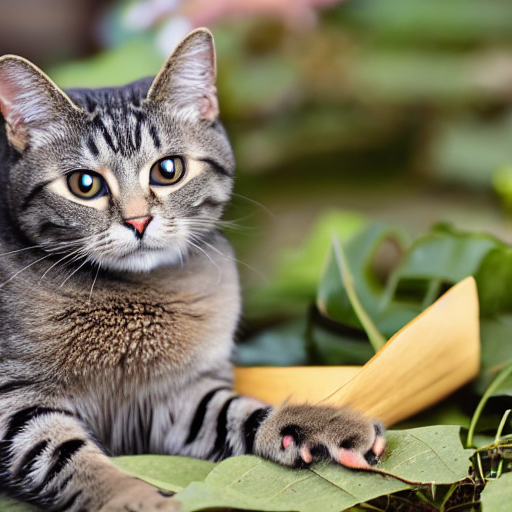

In [16]:
image

In [17]:
%pip install open_clip_torch -q

Note: you may need to restart the kernel to use updated packages.


In [18]:
import open_clip
from transformers import pipeline as hf_pipeline

In [19]:
import time

In [20]:
OUTPUT_DIR = "/kaggle/working/sag_evaluation"
IMAGE_DIR = os.path.join(OUTPUT_DIR, "images")
os.makedirs(IMAGE_DIR, exist_ok=True)

In [21]:

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

NUM_INFERENCE_STEPS = 50
GUIDANCE_SCALE = 7.5
SAG_SCALE=1.0
SEEDS = [10, 20, 30, 40, 50]

PROMPTS = [
    {
        "prompt": "a black cat chasing a butterfly in a desert",
        "objects": ["cat", "butterfly"],
        #"token_indices": [3, 6],
    },
    {
        "prompt": "a man and a woman sitting in a cafe",
        "objects": ["man", "woman"],
        #"token_indices": [2, 5, 9],
    },
    {
        "prompt": "a dog and a cat in a garden with flowers",
        "objects": ["dog", "cat", "flowers"],
        #"token_indices": [2,5, 10],
    },
    {
        "prompt": "a black motorcyle and a red car",
        "objects": ["motorcycle", "car"],
        #"token_indices": [3,7],
    },
    {
        "prompt": "a 19th century ship in an ocean",
        "objects": ["ship"],
        #"token_indices": [2, 4],
    },
    {
        "prompt": "a banana and an apple",
        "objects": ["banana", "apple"],
        #"token_indices": [2,5],
    },
]

# for item in PROMPTS:
#     print("Prompt:", item["prompt"])

pipe.set_progress_bar_config(disable=True)

In [22]:
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32", pretrained="laion2b_s34b_b79k"
)
clip_tokenizer = open_clip.get_tokenizer("ViT-B-32")
clip_model = clip_model.to(DEVICE).eval()

@torch.no_grad()
def clip_scores(image, prompt, objects):
    texts = [prompt] + [f"a photo of a {obj}" for obj in objects]
    image_tensor = clip_preprocess(image.convert("RGB")).unsqueeze(0).to(DEVICE)
    text_tokens = clip_tokenizer(texts).to(DEVICE)

    image_features = clip_model.encode_image(image_tensor)
    text_features = clip_model.encode_text(text_tokens)
    image_features = image_features / image_features.norm(dim=-1, keepdim=True)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)

    scores = (image_features @ text_features.T).squeeze(0).float().cpu().tolist()
    result = {
        "clip_full_prompt": scores[0],
        "clip_min_object": min(scores[1:]) if len(scores) > 1 else scores[0],
    }
    for obj, score in zip(objects, scores[1:]):
        result[f"clip_{obj.replace(' ', '_')}"] = score
    return result


print("CLIP loaded.")

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

CLIP loaded.


In [23]:
%pip install webdataset -q

Note: you may need to restart the kernel to use updated packages.


In [24]:
%pip install ftfy regex tqdm -q
%pip install git+https://github.com/openai/CLIP.git -q

Note: you may need to restart the kernel to use updated packages.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.


In [25]:
import webdataset as wds
from PIL import Image
import io
import matplotlib.pyplot as plt
import os
import json

from warnings import filterwarnings

import numpy as np
import torch
import pytorch_lightning as pl
import torch.nn as nn
from torchvision import datasets, transforms
import tqdm

from os.path import join
from datasets import load_dataset
import pandas as pd
from torch.utils.data import Dataset, DataLoader
import json
import clip
from PIL import Image, ImageFile


In [26]:

class MLP(pl.LightningModule):
    def __init__(self, input_size, xcol='emb', ycol='avg_rating'):
        super().__init__()
        self.input_size = input_size
        self.xcol = xcol
        self.ycol = ycol
        self.layers = nn.Sequential(
            nn.Linear(self.input_size, 1024),
            #nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(1024, 128),
            #nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            #nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(64, 16),
            #nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.layers(x)

    def training_step(self, batch, batch_idx):
            x = batch[self.xcol]
            y = batch[self.ycol].reshape(-1, 1)
            x_hat = self.layers(x)
            loss = F.mse_loss(x_hat, y)
            return loss
    
    def validation_step(self, batch, batch_idx):
        x = batch[self.xcol]
        y = batch[self.ycol].reshape(-1, 1)
        x_hat = self.layers(x)
        loss = F.mse_loss(x_hat, y)
        return loss

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(self.parameters(), lr=1e-3)
        return optimizer

def normalized(a, axis=-1, order=2):
    import numpy as np  # pylint: disable=import-outside-toplevel

    l2 = np.atleast_1d(np.linalg.norm(a, order, axis))
    l2[l2 == 0] = 1
    return a / np.expand_dims(l2, axis)


model = MLP(768)  # CLIP embedding dim is 768 for CLIP ViT L 14

s = torch.load("/kaggle/input/datasets/abhigyanbhatnagar/aesthetic-score-model-weights/saclogosava1-l14-linearMSE.pth")   # load the model you trained previously or the model available in this repo

model.load_state_dict(s)

model.to("cuda")
model.eval()


device = "cuda" if torch.cuda.is_available() else "cpu"
model2, preprocess = clip.load("ViT-L/14", device=device)  #RN50x64   


100%|████████████████████████████████████████| 890M/890M [00:03<00:00, 282MiB/s]


In [27]:
def get_aesthetic_score(image):
    image = preprocess(image).unsqueeze(0).to(device)
    with torch.no_grad():
       image_features = model2.encode_image(image)

    im_emb_arr = normalized(image_features.cpu().detach().numpy() )
    prediction = model(torch.from_numpy(im_emb_arr).to(device).type(torch.cuda.FloatTensor))
    result = round(float(prediction.detach()[0]),3)
    return {"aesthetic_score": result}

    

In [28]:
get_aesthetic_score(image)

{'aesthetic_score': 5.666}

In [31]:
records = []

for item in PROMPTS:
    prompt = item["prompt"]
    objects = [obj.lower() for obj in item["objects"]]

    for seed in SEEDS:
        generator = torch.Generator(device=DEVICE).manual_seed(seed)
        
        if DEVICE == "cuda":
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()
        start = time.perf_counter()
        images = pipe(
                prompt=prompt,
                guidance_scale=GUIDANCE_SCALE,
                generator=generator,
                sag_scale=SAG_SCALE,
                num_inference_steps=NUM_INFERENCE_STEPS,
            ).images
        image = images[0]
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        safe_prompt = "".join(
            ch if ch.isalnum() else "_" for ch in prompt
        ).strip("_")
        image_path = os.path.join(
            IMAGE_DIR, f"{safe_prompt}_seed{seed}.png"
        )
        image.save(image_path)

        row = {
            "prompt": prompt,
            "seed": seed,
            "image_path": image_path,
            "generation_seconds": elapsed,
            "guidance_scale": GUIDANCE_SCALE,
            "sag_scale": SAG_SCALE,
            "num_inference_steps": NUM_INFERENCE_STEPS,
        }

        row.update(clip_scores(image, prompt, objects))
        #update aesthetic score here
        row.update(get_aesthetic_score(image))
        records.append(row)

        # Save after each image so progress is not lost.
        pd.DataFrame(records).to_csv(
            os.path.join(OUTPUT_DIR, "per_image_results.csv"),
            index=False,
        )

        del image, generator
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
            

print("Finished. Images and per-image CSV saved in:", OUTPUT_DIR)

Finished. Images and per-image CSV saved in: /kaggle/working/sag_evaluation


In [32]:
!zip -r /kaggle/working/output.zip /kaggle/working/"sag_evaluation"

  adding: kaggle/working/sag_evaluation/ (stored 0%)
  adding: kaggle/working/sag_evaluation/per_image_results.csv (deflated 72%)
  adding: kaggle/working/sag_evaluation/images/ (stored 0%)
  adding: kaggle/working/sag_evaluation/images/a_black_cat_chasing_a_butterfly_in_a_desert_seed20.png (deflated 0%)
  adding: kaggle/working/sag_evaluation/images/a_man_and_a_woman_sitting_in_a_cafe_seed40.png (deflated 0%)
  adding: kaggle/working/sag_evaluation/images/a_19th_century_ship_in_an_ocean_seed50.png (deflated 0%)
  adding: kaggle/working/sag_evaluation/images/a_19th_century_ship_in_an_ocean_seed30.png (deflated 0%)
  adding: kaggle/working/sag_evaluation/images/a_black_cat_chasing_a_butterfly_in_a_desert_seed10.png (deflated 0%)
  adding: kaggle/working/sag_evaluation/images/a_man_and_a_woman_sitting_in_a_cafe_seed10.png (deflated 0%)
  adding: kaggle/working/sag_evaluation/images/a_banana_and_an_apple_seed50.png (deflated 1%)
  adding: kaggle/working/sag_evaluation/images/a_man_and_a_w